# CS156 — Session 8: Gradients and Backpropagation

## Introduction

In the previous session, I learned how feed-forward neural networks combine inputs, weights, biases, and activation functions to make predictions. This session focuses on how these networks learn; specifically, I examine how gradients are calculated and used to update model parameters.

A gradient describes how a function changes when its inputs or parameters change. In machine learning, gradients help us identify which direction to adjust the parameters to reduce the loss, which measures the model's error.

The main ideas covered in this session are:

1. **Forward propagation:** Calculating the output of a neural network using its current parameters.
2. **Backpropagation:** Applying the chain rule to calculate how the output or loss changes with respect to each parameter.
3. **Vectorization:** Using vectors instead of separate scalar variables to make the calculations more efficient.
4. **Automatic differentiation:** Using JAX to calculate gradients without manually deriving every step.
5. **Gradient descent:** Repeatedly updating parameters to reduce the loss.

The general gradient descent update is:

$$
\theta_{\text{new}} = \theta_{\text{old}} - \eta \nabla_{\theta}\mathcal{L}
$$

Here:

- $\theta$ represents the model parameters.
- $\eta$ is the learning rate, which controls the size of each update.
- $\mathcal{L}$ is the loss function.
- $\nabla_{\theta}\mathcal{L}$ is the gradient of the loss with respect to the parameters.

The negative gradient gives the direction of steepest local decrease in the loss. By repeating this process, we can gradually improve the model's predictions.

# Question 1 of 3 — Basic Prep: Math Exercise: Sigmoid Example

## Q1. Gradient of the Sigmoid

### Question 1(a): Write down the formula for the derivative of the sigmoid function.

The sigmoid function converts a real-valued input into an output between 0 and 1.

$$
f = \sigma(z) = \frac{1}{1+e^{-z}}
$$

For the example in this exercise:

$$
z = w_0x_0+w_1x_1+w_2
$$

The derivative of the sigmoid function is:

$$
\frac{df}{dz} = \sigma(z)(1-\sigma(z))
$$

Since $f=\sigma(z)$, this simplifies to:

$$
\boxed{\frac{df}{dz}=f(1-f)}
$$

### Question 1(b): Why is writing the derivative as $f(1-f)$ useful?

This expression allows us to reuse the sigmoid output calculated during the forward pass, rather than calculating the exponential again. It reduces unnecessary operations and makes the backward pass more efficient.

The sigmoid derivative also has an important property:

$$
0 < \frac{df}{dz} \leq 0.25
$$

The derivative is largest when the sigmoid output is 0.5. However, when the output approaches 0 or 1, the derivative becomes very small.

### My Interpretation

I understand that the derivative measures how sensitive the sigmoid output is to changes in its input. When the sigmoid output is near 0.5, a small change in the input has a relatively large effect. When it is close to 0 or 1, the output changes very little.

This helps explain why sigmoid neurons can experience vanishing gradients; when several derivatives are small, multiplying them during backpropagation can produce an extremely small gradient.

### Feedback and Reflection

My original derivation was correct. The feedback also highlighted the importance of sigmoid saturation, which connects a simple derivative calculation to a larger problem in neural network training.

## Q2. Gradients on Inputs and Weights

### Question 2(a): Write the gradient of the neuron output with respect to a weight and an input.

Consider the weighted sum:

$$
z = \sum_i w_ix_i+b
$$

The derivative of the weighted sum with respect to a weight is:

$$
\frac{\partial z}{\partial w_i}=x_i
$$

Similarly, the derivative with respect to an input is:

$$
\frac{\partial z}{\partial x_i}=w_i
$$

Using the chain rule, I obtain:

$$
\boxed{\frac{\partial f}{\partial w_i}
=\frac{\partial f}{\partial z}x_i}
$$

$$
\boxed{\frac{\partial f}{\partial x_i}
=\frac{\partial f}{\partial z}w_i}
$$

Since the neuron uses a sigmoid activation:

$$
\frac{\partial f}{\partial z}=f(1-f)
$$

Therefore:

$$
\frac{\partial f}{\partial w_i}=f(1-f)x_i
$$

$$
\frac{\partial f}{\partial x_i}=f(1-f)w_i
$$

If the network has a loss function $\mathcal{L}$, I must also include the gradient flowing backward from the loss:

$$
\frac{\partial \mathcal{L}}{\partial w_i}
=
\frac{\partial \mathcal{L}}{\partial f}
\frac{\partial f}{\partial z}x_i
$$

### Question 2(b): Why does the input $x_i$ appear in the weight gradient?

The input appears because the weighted sum depends directly on the product $w_ix_i$. Therefore, the effect of changing a weight is proportional to its corresponding input.

### My Interpretation

A weight determines how strongly an input contributes to a neuron's calculation. Its gradient depends on the input value and the gradient received from the next operation.

For example, a large input can produce a larger weight gradient if the other terms remain unchanged. If an input is zero, changing its corresponding weight does not affect that neuron's weighted sum for that observation.

### Feedback and Reflection

My answers correctly applied the chain rule. However, I also learned to distinguish between the gradient of the neuron output and the gradient of the loss. The second includes an additional derivative because the loss depends on the neuron output.

## Q3. Jacobians and Backpropagation

### Question 3(a): What is a Jacobian matrix?

A Jacobian is a matrix containing all the first-order partial derivatives of a vector-valued function.

For a function:

$$
f:\mathbb{R}^{n}\rightarrow\mathbb{R}^{m}
$$

The Jacobian is an $m\times n$ matrix:

$$
J_{ij}=\frac{\partial f_i}{\partial x_j}
$$

Each entry describes how one output changes when one input changes.

### Question 3(b): Why do neural networks use vector-Jacobian products instead of calculating full Jacobian matrices?

Neural networks can contain millions of parameters. Constructing every Jacobian explicitly would require substantial computation and memory.

Instead, backpropagation calculates vector-Jacobian products (VJPs). These products combine an upstream gradient with the local derivatives of an operation.

Using column-vector notation:

$$
\nabla_x \mathcal{L}=J^T\nabla_y\mathcal{L}
$$

Here, $J$ is the Jacobian of $y$ with respect to $x$.

This approach calculates the gradients needed for training without explicitly storing the entire Jacobian at every layer.

### Question 3(c): What does the vector represent in a vector-Jacobian product?

The vector represents the upstream gradient, which describes how the loss changes with respect to the outputs of the current operation.

Backpropagation combines this gradient with local derivatives to determine how the loss changes with respect to earlier inputs and parameters.

### My Interpretation

I understand a Jacobian as a collection of derivatives that describes the relationship between multiple inputs and outputs. A gradient describes the change of a scalar function, while a Jacobian extends the idea to functions with multiple outputs.

In a neural network, backpropagation does not need to construct every Jacobian explicitly. Instead, it applies the chain rule from the final loss toward the earlier layers, calculating the gradients required to update the weights.

### Feedback and Reflection

The feedback confirmed that my definitions were correct. The main improvement was to connect the mathematical definition of a Jacobian to its practical purpose: computing neural network gradients efficiently.

# Question 2 of 3 — Q2A: Coding Exercise: Sigmoid Example (3)

## Exercise 3.1 and Exercise 3.2: Forward and Backward Passes

### Question

Calculate all the derivatives in the sigmoid computation graph, starting at the final output. Then complete the Python code for the backward pass.

### My Approach and Justification

I first calculate the output of the sigmoid neuron using the forward pass. Next, I work backward through the same operations and apply the chain rule to determine how the final output changes with respect to each weight and input.

I keep the intermediate values from the forward pass because they are needed when calculating the local derivatives during backpropagation.

The neuron uses the following equations:

$$
z=w_0x_0+w_1x_1+w_2
$$

$$
f=\frac{1}{1+e^{-z}}
$$

The initial values are:

$$
w_0=2,\quad w_1=-3,\quad w_2=-3
$$

$$
x_0=-1,\quad x_1=-2
$$

Substituting these values gives:

$$
z=2(-1)+(-3)(-2)-3=1
$$

Therefore:

$$
f=\sigma(1)\approx0.7311
$$

The backward pass starts with:

$$
\frac{df}{df}=1
$$

This is because the derivative of a value with respect to itself is always 1. From there, I calculate each earlier derivative using the chain rule.

In this exercise, I am differentiating the neuron output itself, not a separate loss function.

In [1]:
import numpy as np

# Setting the weights and inputs
w0, w1, w2 = 2.00, -3.00, -3.00
x0, x1 = -1.00, -2.00

# Computing the weighted sum during the forward pass
mul0 = w0 * x0
mul1 = w1 * x1
sum01 = mul0 + mul1
sum012 = sum01 + w2

# Applying the sigmoid function one step at a time
neg = -sum012
exp = np.exp(neg)
plus1 = exp + 1
invert = 1 / plus1

# Starting backpropagation with df/df = 1
# Applying the chain rule through each earlier operation
d_invert = 1.00
d_plus1 = d_invert * (-1 / plus1**2)
d_exp = d_plus1 * 1
d_neg = d_exp * exp
d_sum012 = d_neg * (-1)

# Passing the gradient through the addition operations
d_w2, d_sum01 = d_sum012, d_sum012
d_mul0, d_mul1 = d_sum01, d_sum01

# Calculating derivatives with respect to weights and inputs
d_w0, d_x0 = d_mul0 * x0, d_mul0 * w0
d_w1, d_x1 = d_mul1 * x1, d_mul1 * w1

# Displaying the output and calculated derivatives
print(f"Sigmoid output: {invert:.6f}")
print(f"df/dw0: {d_w0:.6f}")
print(f"df/dw1: {d_w1:.6f}")
print(f"df/dw2: {d_w2:.6f}")
print(f"df/dx0: {d_x0:.6f}")
print(f"df/dx1: {d_x1:.6f}")
print(f"df/dz: {d_sum012:.6f}")

Sigmoid output: 0.731059
df/dw0: -0.196612
df/dw1: -0.393224
df/dw2: 0.196612
df/dx0: 0.393224
df/dx1: -0.589836
df/dz: 0.196612


### My Interpretation

The forward pass produces a sigmoid output of approximately 0.7311. This matches the expected result from the original example.

During the backward pass, I calculate the derivative of the output with respect to each intermediate value. The derivative with respect to the weighted sum is approximately 0.1966, which agrees with the sigmoid derivative:

$$
\frac{df}{dz}=f(1-f)\approx0.1966
$$

The gradients with respect to the weights are:

$$
\frac{\partial f}{\partial w_0}\approx-0.1966
$$

$$
\frac{\partial f}{\partial w_1}\approx-0.3932
$$

$$
\frac{\partial f}{\partial w_2}\approx0.1966
$$

These values tell me how the sigmoid output changes when I slightly change each weight, while keeping the other values fixed.

For example, the negative gradient for $w_0$ means that increasing this weight slightly would decrease the output near its current value. In contrast, increasing $w_2$ would increase the output.

### Why This Approach Is Useful

I used separate multiplication and addition operations to understand exactly how backpropagation works. Although this approach requires more code, it makes the chain rule visible at every step.

The main takeaway is that backpropagation works locally. Instead of differentiating the entire expression at once, I calculate each local derivative and multiply it by the gradient received from the next operation.

# Question 2 of 3 — Q2B: Coding Exercise: Calculus Derivation

## Exercise: Calculate the Gradient with Respect to the Weight Vector

### Question

Given the function:

$$
f(w,x)=w^Tx
$$

Calculate the derivative of $f$ with respect to every component of the weight vector $w$.

### My Approach and Derivation

I first express the dot product as a sum of individual terms.

Let the weight and input vectors be:

$$
w=
\begin{bmatrix}
w_1\\
w_2\\
w_3
\end{bmatrix}
\qquad
x=
\begin{bmatrix}
x_1\\
x_2\\
x_3
\end{bmatrix}
$$

The function becomes:

$$
f(w,x)=w_1x_1+w_2x_2+w_3x_3
$$

To calculate the gradient with respect to $w$, I differentiate the function with respect to each weight separately.

For the first weight:

$$
\frac{\partial f}{\partial w_1}=x_1
$$

For the second weight:

$$
\frac{\partial f}{\partial w_2}=x_2
$$

For the third weight:

$$
\frac{\partial f}{\partial w_3}=x_3
$$

This happens because each weight is multiplied by its corresponding input, while the remaining terms are constant with respect to that weight.

Combining the derivatives into a vector gives:

$$
\nabla_w f=
\begin{bmatrix}
\frac{\partial f}{\partial w_1}\\
\frac{\partial f}{\partial w_2}\\
\frac{\partial f}{\partial w_3}
\end{bmatrix}
=
\begin{bmatrix}
x_1\\
x_2\\
x_3
\end{bmatrix}
$$

Therefore:

$$
\boxed{\nabla_w f=x}
$$

Similarly, differentiating with respect to the input vector gives:

$$
\boxed{\nabla_x f=w}
$$

### My Interpretation

The gradient of a dot product with respect to its weights is simply the input vector. Similarly, the gradient with respect to the inputs is the weight vector.

This result is important because neural networks often calculate weighted sums involving hundreds or thousands of inputs. Rather than calculating every derivative separately, I can use vector operations to obtain all the gradients together.

### Justification

I used the component-wise derivation first because it explains where the vector gradient comes from. Once I understand the individual derivatives, combining them into a vector is straightforward.

In [2]:
# Checking the dot-product derivative with a three-element example
w_demo = np.array([2.0, -3.0, 1.0])
x_demo = np.array([-1.0, -2.0, 4.0])

# Computing the dot product and its analytical gradients
f_demo = w_demo.T @ x_demo
grad_w = x_demo
grad_x = w_demo

# Displaying the results
print("Dot product:", f_demo)
print("Gradient with respect to w:", grad_w)
print("Gradient with respect to x:", grad_x)

Dot product: 8.0
Gradient with respect to w: [-1. -2.  4.]
Gradient with respect to x: [ 2. -3.  1.]


# Question 3 of 3 — Core Questions: Coding Exercise: Sigmoid Example (Vectorized)

## Exercise: Complete the Backward Pass Using Vectors

### Question

Rewrite the sigmoid calculation so that the weights and inputs are vectors. Complete the backward pass and calculate the gradients with respect to both vectors.

### My Approach and Justification

In the previous exercise, I calculated each multiplication and addition separately. However, this approach becomes difficult when the number of input features increases.

To address this, I use NumPy arrays to represent the weights and inputs as vectors. I then replace the separate multiplication and addition operations with a dot product.

The equation becomes:

$$
z=w^Tx+b
$$

The sigmoid output is:

$$
f=\sigma(z)=\frac{1}{1+e^{-z}}
$$

I can calculate the gradients using the chain rule and the dot-product derivatives derived in Q2B.

For the weights:

$$
\boxed{\frac{\partial f}{\partial w}
=\frac{\partial f}{\partial z}x}
$$

For the inputs:

$$
\boxed{\frac{\partial f}{\partial x}
=\frac{\partial f}{\partial z}w}
$$

For the bias:

$$
\boxed{\frac{\partial f}{\partial b}
=\frac{\partial f}{\partial z}}
$$

The underlying mathematics remains unchanged; only the implementation becomes more compact.

### Why I Chose Vectorization

Vectorization allows me to calculate multiple gradients without writing separate variables for every weight and input. It also makes the code easier to extend to larger datasets and neural networks.

In [3]:
# Setting vector weights, bias, and inputs
w = np.array([2.00, -3.00])
b = -3.00
x = np.array([-1.00, -2.00])

# Computing the vectorized forward pass
dot = w.T @ x
summed = dot + b
neg = -summed
exp = np.exp(neg)
plus1 = exp + 1
invert = 1 / plus1

# Calculating the backward pass through the sigmoid
d_invert = 1.00
d_plus1 = d_invert * (-1 / plus1**2)
d_exp = d_plus1 * 1
d_neg = d_exp * exp
d_summed = d_neg * (-1)

# Sending the gradient through the bias and dot product
d_b, d_dot = d_summed, d_summed

# Calculating the vector gradients
d_w = d_dot * x
d_x = d_dot * w

# Checking the results against the scalar implementation
print(f"Sigmoid output: {invert:.6f}")
print("Weight gradients:", d_w)
print("Input gradients:", d_x)
print(f"Bias gradient: {d_b:.6f}")

assert np.allclose(d_w, [d_w0, d_w1])
assert np.isclose(d_b, d_w2)

Sigmoid output: 0.731059
Weight gradients: [-0.19661193 -0.39322387]
Input gradients: [ 0.39322387 -0.5898358 ]
Bias gradient: 0.196612


### My Interpretation

The vectorized implementation produces the same sigmoid output as the original scalar implementation:

$$
f\approx0.7311
$$

The gradient with respect to the weight vector is:

$$
\nabla_w f\approx
\begin{bmatrix}
-0.1966\\
-0.3932
\end{bmatrix}
$$

The gradient with respect to the bias is approximately 0.1966.

These values match the derivatives calculated in Q2A, confirming that vectorization does not change the mathematical result.

### Why This Matters

I find this version more practical because it avoids defining a separate variable for every feature. For example, an image with 784 pixel features could be represented as a vector, rather than requiring 784 separate input variables.

This exercise also connects directly to the calculus derivation in Q2B. The expressions for the weight and input gradients remain the same, regardless of the number of features.

### Reflection

The main difference between the scalar and vectorized implementations is how the calculations are organized. The scalar version makes each derivative easier to follow, while the vectorized version is better suited for larger machine learning models.

# Preview: Auto-Magic Gradients with JAX

## Exercise: Calculate Sigmoid Gradients Automatically

### Question

Use JAX to define the sigmoid forward pass and automatically calculate the gradients with respect to the model parameters.

### My Approach and Justification

In the previous exercises, I manually calculated each gradient using the chain rule. Although this helped me understand backpropagation, writing every derivative separately would become difficult for a larger neural network.

To address this, I use JAX, a Python library that supports automatic differentiation.

Automatic differentiation allows me to calculate gradients directly from the operations defined in a function. Instead of writing separate backward-pass equations, I only need to define the forward pass and use `jax.grad()`.

The sigmoid equation remains the same:

$$
f=\sigma(w^Tx+b)
$$

I use JAX's NumPy-like functions to implement this equation. Then, I calculate the gradients with respect to the weights and bias.

### Why I Chose JAX

JAX makes it possible to calculate derivatives automatically while preserving the mathematical structure of my original implementation. This allows me to compare the automatically calculated gradients with my manual results.

It also supports computations on CPUs, GPUs, and TPUs, making it useful for larger machine learning applications.

In [4]:
import jax
import jax.numpy as jnp

# Defining the forward pass using JAX-compatible operations
def sigmoid_example(params, x):
    dot = params["w"].T @ x
    summed = dot + params["b"]
    neg = -summed
    exp = jnp.exp(neg)
    plus1 = exp + 1
    invert = 1 / plus1
    return invert

# Preparing the model parameters and input
params = {"w": jnp.array([2.00, -3.00]), "b": jnp.array(-3.00)}
x_jax = jnp.array([-1.00, -2.00])

# Checking the forward-pass output
jax_output = sigmoid_example(params, x_jax)
print("JAX sigmoid output:", float(jax_output))

JAX sigmoid output: 0.7310585975646973


In [5]:
# Creating a function that differentiates the sigmoid output
# Calculating gradients with respect to the parameter dictionary
grad_sigmoid_example = jax.grad(sigmoid_example)
jax_grads = grad_sigmoid_example(params, x_jax)

# Displaying the gradients calculated automatically
print("JAX bias gradient:", float(jax_grads["b"]))
print("JAX weight gradients:", np.asarray(jax_grads["w"]))

# Confirming agreement with the manual vectorized gradients
assert np.allclose(np.asarray(jax_grads["w"]), d_w, atol=1e-6)
assert np.isclose(float(jax_grads["b"]), d_b, atol=1e-6)

JAX bias gradient: 0.19661197066307068
JAX weight gradients: [-0.19661197 -0.39322394]


### My Interpretation

JAX produces a sigmoid output of approximately 0.7311, which matches both my scalar and vectorized implementations.

The automatically calculated gradients are:

$$
\frac{\partial f}{\partial b}\approx0.1966
$$

$$
\nabla_w f\approx
\begin{bmatrix}
-0.1966\\
-0.3932
\end{bmatrix}
$$

These values also agree with my earlier calculations.

This confirms that the manual backpropagation process and automatic differentiation produce the same mathematical results, apart from small differences in numerical precision.

### Why Automatic Differentiation Is Useful

Manual backpropagation requires me to derive and implement each derivative. In contrast, JAX tracks the mathematical operations in the forward pass and calculates the gradients automatically.

This makes the implementation easier to maintain, especially as the number of layers and parameters increases.

### Reflection

I used manual backpropagation first because I wanted to understand how the gradients were calculated. JAX then allowed me to verify those results without manually repeating the backward pass.

However, the function being differentiated here is still the sigmoid output, not a training loss. The next exercise introduces a loss function and uses its gradients to update the model parameters.

# Extensions: Coding Exercise — Training (4)

## Exercise: Run Gradient Descent for 1,000 Iterations

### Question

Extend the sigmoid example by creating a function that repeatedly updates the weights so that the sigmoid output approaches zero.

The exercise requires:

1. Calculating the gradient at every iteration.
2. Updating the weights after each iteration.
3. Choosing a learning rate.
4. Repeating the process for 1,000 iterations.

### My Approach and Justification

In the earlier exercises, I calculated the gradients of the sigmoid output but did not update the parameters.

In this exercise, I use gradient descent to adjust the weights and bias. My objective is to make the sigmoid output approach a target value of zero.

First, I define a squared-error loss function:

$$
\mathcal{L}=\frac{1}{2}(f-t)^2
$$

Here:

- $f$ is the sigmoid prediction.
- $t$ is the target value, which is 0.
- $\mathcal{L}$ measures the difference between the prediction and target.

The factor of $\frac{1}{2}$ simplifies the derivative.

### Step 1: Calculate the Loss Gradient

The derivative of the loss with respect to the prediction is:

$$
\frac{\partial \mathcal{L}}{\partial f}=f-t
$$

Since the sigmoid derivative is:

$$
\frac{\partial f}{\partial z}=f(1-f)
$$

I apply the chain rule:

$$
\frac{\partial \mathcal{L}}{\partial z}
=
\frac{\partial \mathcal{L}}{\partial f}
\frac{\partial f}{\partial z}
$$

Therefore:

$$
\boxed{
\frac{\partial \mathcal{L}}{\partial z}
=(f-t)f(1-f)
}
$$

### Step 2: Calculate the Parameter Gradients

For the weights:

$$
\boxed{
\nabla_w\mathcal{L}
=
\frac{\partial\mathcal{L}}{\partial z}x
}
$$

For the bias:

$$
\boxed{
\frac{\partial\mathcal{L}}{\partial b}
=
\frac{\partial\mathcal{L}}{\partial z}
}
$$

### Step 3: Update the Parameters

I update the weights by moving in the negative direction of the loss gradient:

$$
w_{\text{new}}=w_{\text{old}}-\eta\nabla_w\mathcal{L}
$$

Similarly, I update the bias:

$$
b_{\text{new}}
=
b_{\text{old}}
-
\eta\frac{\partial\mathcal{L}}{\partial b}
$$

I choose a learning rate of:

$$
\eta=0.1
$$

This gives relatively small parameter updates in the current example.

### Step 4: Repeat for 1,000 Iterations

I repeat the forward pass, backward pass, and parameter updates for 1,000 iterations. I also calculate the loss at every iteration so I can monitor whether the model is improving.

### Why I Used This Approach

I use squared-error loss because it provides a simple way to measure the difference between the sigmoid output and the desired target.

I also calculate the gradients manually rather than using JAX for training. This allows me to connect the derivative calculations from the earlier exercises directly to the gradient descent updates.

In [6]:
# Defining the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Defining a reusable gradient descent training function
def train_sigmoid(w, b, x, target=0.0, eta=0.1, n_iter=1000):
    w = w.copy()
    losses = []

    for i in range(n_iter):
        # Computing the prediction with the current parameters
        dot = w.T @ x + b
        f = sigmoid(dot)

        # Measuring squared error against the target
        loss = 0.5 * (f - target)**2
        losses.append(loss)

        # Applying the chain rule from loss to parameters
        d_f = f - target
        d_dot = d_f * f * (1 - f)
        d_w = d_dot * x
        d_b = d_dot

        # Updating the weights and bias with gradient descent
        w -= eta * d_w
        b -= eta * d_b

        # Showing progress after every 100 iterations
        if i % 100 == 0:
            print(f"iter {i}, f={f:.4f}, loss={loss:.4f}, w={w}, b={b:.4f}")

    # Recalculating the output after the final parameter update
    final_f = sigmoid(w.T @ x + b)
    final_loss = 0.5 * (final_f - target)**2
    return w, b, final_f, final_loss, losses

# Initializing the original example's values
x_train = np.array([-1.0, -2.0])
w_start = np.array([2.0, -3.0])
b_start = -3.0

# Training for 1,000 iterations
w_final, b_final, f_final, loss_final, losses = train_sigmoid(w_start, b_start, x_train)

# Displaying the final parameters, output, and loss
print(f"Final output: {f_final:.6f}")
print("Final weights:", w_final)
print(f"Final bias: {b_final:.6f}")
print(f"Final loss: {loss_final:.6f}")

iter 0, f=0.7311, loss=0.2672, w=[ 2.01437348 -2.97125303], b=-3.0144
iter 100, f=0.1181, loss=0.0070, w=[ 2.50301232 -1.99397536], b=-3.5030
iter 200, f=0.0765, loss=0.0029, w=[ 2.58232644 -1.83534713], b=-3.5823
iter 300, f=0.0603, loss=0.0018, w=[ 2.62484135 -1.7503173 ], b=-3.6248
iter 400, f=0.0511, loss=0.0013, w=[ 2.65376944 -1.69246111], b=-3.6538
iter 500, f=0.0451, loss=0.0010, w=[ 2.67563893 -1.64872213], b=-3.6756
iter 600, f=0.0408, loss=0.0008, w=[ 2.69319331 -1.61361339], b=-3.6932
iter 700, f=0.0375, loss=0.0007, w=[ 2.70784108 -1.58431783], b=-3.7078
iter 800, f=0.0348, loss=0.0006, w=[ 2.72040005 -1.55919989], b=-3.7204
iter 900, f=0.0327, loss=0.0005, w=[ 2.73138659 -1.53722682], b=-3.7314
Final output: 0.030879
Final weights: [ 2.74105493 -1.51789014]
Final bias: -3.741055
Final loss: 0.000477


### My Interpretation

The gradient descent implementation successfully reduces the sigmoid output over 1,000 iterations.

Initially, the sigmoid output is approximately:

$$
f_{\text{initial}}\approx0.7311
$$

After training, it becomes:

$$
f_{\text{final}}\approx0.0309
$$

The final output is much closer to the target value of zero, showing that the parameter updates have reduced the prediction error.

The squared-error loss also decreases substantially. This confirms that gradient descent is moving the parameters in a direction that improves the model according to the chosen objective.

### Understanding the Weight Updates

During each iteration, I calculate the prediction using the current weights and bias. Next, I calculate the loss and use backpropagation to determine how the loss changes with respect to those parameters.

I then subtract the gradients multiplied by the learning rate.

The process repeats using the updated parameters, allowing the model to gradually reduce its error.

### Why the Output Does Not Reach Exactly Zero

The final output approaches zero but does not reach it exactly.

This is expected because the sigmoid function produces values strictly between 0 and 1 for finite inputs.

$$
0<\sigma(z)<1
$$

To make the sigmoid output approach zero, the weighted sum must become increasingly negative.

### Reflection

This exercise helped me understand the difference between calculating gradients and using gradients for optimization.

Backpropagation calculates the gradients, while gradient descent uses those gradients to update the parameters.

The earlier exercises focused on the derivatives of the sigmoid output. In this exercise, I calculate the derivatives of the loss instead, allowing the model to learn from the difference between its prediction and the target.

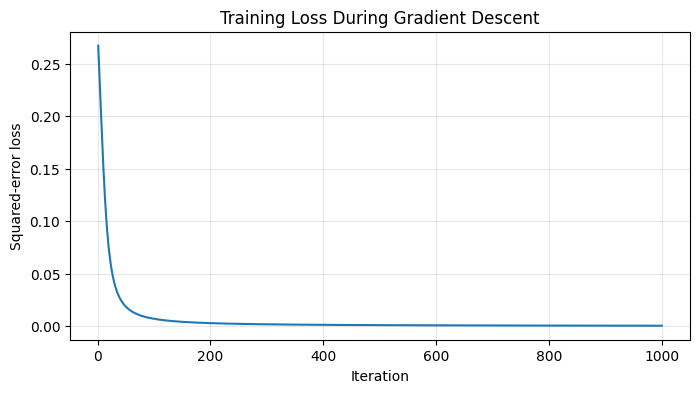

In [7]:
import matplotlib.pyplot as plt

# Plotting the recorded loss across training iterations
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(losses) + 1), losses)
plt.xlabel("Iteration")
plt.ylabel("Squared-error loss")
plt.title("Training Loss During Gradient Descent")
plt.grid(alpha=0.3)
plt.show()

## Interpretation of the Training Loss Curve

The loss curve shows how the model's prediction error changes over 1,000 iterations.

The loss decreases rapidly during the earlier iterations because the initial prediction is relatively far from the target. As training continues, the rate of improvement becomes slower.

This pattern is consistent with the decreasing gradients as the sigmoid output approaches zero.

The curve also helps me evaluate the optimization process. Since the loss decreases over the recorded iterations, the learning rate of 0.1 works for this particular example.

However, this does not mean that the same learning rate would be suitable for every model. Different datasets, model architectures, and loss functions may require different learning rates.

# Session 8 — Final Reflection

This session helped me connect the mathematical foundations of derivatives to the practical process of training neural networks.

I began by examining the sigmoid function and calculating its derivative. Next, I applied the chain rule to calculate how the output changes with respect to the weights and inputs. By working through individual operations, I was able to understand how backpropagation moves from the final output toward the earlier parts of a computation.

I then used vectorization to simplify the implementation. Although the code became shorter, the gradients remained the same, confirming that vector operations provide a more efficient representation of the same mathematics.

The JAX exercise introduced automatic differentiation, which allowed me to calculate the gradients without manually implementing the backward pass. Comparing the results with my earlier calculations helped me verify my understanding.

Finally, I implemented gradient descent to update the parameters over 1,000 iterations. The sigmoid output moved from approximately 0.7311 to 0.0309, while the loss decreased substantially.

My main takeaway is that backpropagation and gradient descent perform different but related tasks. Backpropagation calculates how the loss changes with respect to the parameters, while gradient descent uses those gradients to update the parameters and improve the model.

Together, these ideas explain an important part of how neural networks learn from data.